# Ride Match Prediction using K-Nearest Neighbors (KNN)
**Project:** AI-Enhanced Car Pooling Application  
**Task:** classify a (passenger request, offered ride) pair as **Best Match / Suitable Match / Low Match**.

Steps: 1) load data → 2) explore → 3) preprocess & encode → 4) train KNN → 5) evaluate → 6) save with joblib → 7) test the saved model.

In [1]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from features import FEATURE_COLUMNS, LABELS, build_feature_row

## 1. Dataset
`ride_dataset.csv` is produced by `generate_dataset.py` (3000 simulated passenger↔ride pairs). Each row has the 6 input features required by the brief and the target `match_label` (0=Low, 1=Suitable, 2=Best).

In [2]:
df = pd.read_csv('ride_dataset.csv')
print(df.shape)
df.head()

(3000, 7)


,pickup_distance_km,destination_distance_km,time_diff_min,seats_available,preference_score,driver_rating,match_label
0,8.20,6.26,11.0,4,2,2.7,1
1,1.49,0.88,194.0,4,0,3.4,1
2,10.25,5.44,68.0,3,1,3.3,0
3,2.82,2.48,24.0,3,3,3.5,2
4,0.21,0.44,108.0,2,3,4.2,2


In [3]:
print(df.isna().sum().sum(), 'missing values')
df.describe().round(2)

0 missing values


,pickup_distance_km,destination_distance_km,time_diff_min,seats_available,preference_score,driver_rating,match_label
count,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00
mean,5.40,5.60,100.22,3.52,1.49,3.98,1.04
std,5.41,5.53,111.69,1.69,1.12,0.67,0.73
min,0.00,0.00,0.00,1.00,0.00,1.00,0.00
25%,1.12,1.24,14.00,2.00,0.00,3.50,1.00
50%,2.33,2.38,29.00,4.00,1.00,4.00,1.00
75%,9.51,9.99,182.50,5.00,2.00,4.50,2.00
max,18.00,17.99,360.00,6.00,3.00,5.00,2.00


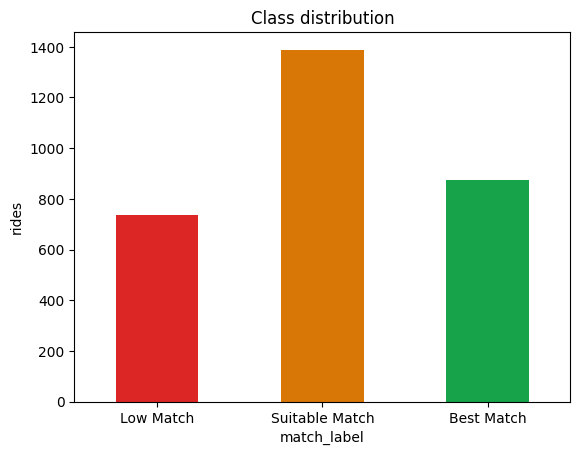

In [4]:
df['match_label'].map(dict(enumerate(LABELS))).value_counts().reindex(LABELS).plot(kind='bar', color=['#dc2626','#d97706','#16a34a'])
plt.title('Class distribution'); plt.ylabel('rides'); plt.xticks(rotation=0); plt.show()

## 2. Preprocessing and encoding
Raw ride data contains **place names** (pickup / destination), **timings** and **boolean preferences**. They are encoded into numbers:

| Raw input | Encoded feature |
|---|---|
| Pickup location (text) | `pickup_distance_km` – distance between passenger pickup and ride pickup (haversine on lat/long) |
| Destination (text) | `destination_distance_km` |
| Travel timing | `time_diff_min` – minutes between wanted time and departure |
| Available seats | `seats_available` |
| Passenger preferences (AC / no-smoking / music) | `preference_score` – how many of 3 are satisfied |
| Previous ride ratings | `driver_rating` – average rating |

The same function `build_feature_row()` is used by the backend, so training and prediction are consistent. KNN is distance based, so we also **standardise** the features (`StandardScaler`).

In [5]:
X, y = df[FEATURE_COLUMNS], df['match_label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(2400, 6) (600, 6)


## 3. Choosing K and training the KNN model
Grid-search with 5-fold cross validation over `k` and the weighting scheme.

In [6]:
pipe = Pipeline([('scale', StandardScaler()), ('knn', KNeighborsClassifier())])
grid = GridSearchCV(pipe, {'knn__n_neighbors':[3,5,7,9,11,15], 'knn__weights':['uniform','distance']}, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)
print('Best params:', grid.best_params_, '| CV accuracy: %.4f' % grid.best_score_)
model = grid.best_estimator_

Best params: {'knn__n_neighbors': 9, 'knn__weights': 'distance'} | CV accuracy: 0.8396


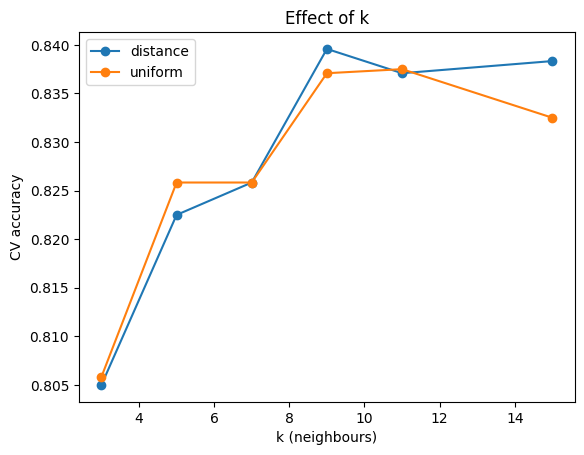

In [7]:
res = pd.DataFrame(grid.cv_results_)
for w, g in res.groupby('param_knn__weights'):
    plt.plot(g['param_knn__n_neighbors'], g['mean_test_score'], marker='o', label=w)
plt.xlabel('k (neighbours)'); plt.ylabel('CV accuracy'); plt.legend(); plt.title('Effect of k'); plt.show()

## 4. Evaluation on unseen test data

In [8]:
pred = model.predict(X_test)
print('Accuracy: %.4f' % accuracy_score(y_test, pred))
print(classification_report(y_test, pred, target_names=LABELS))

Accuracy: 0.8317
                precision    recall  f1-score   support

     Low Match       0.92      0.74      0.82       148
Suitable Match       0.79      0.87      0.83       278
    Best Match       0.85      0.84      0.85       174

      accuracy                           0.83       600
     macro avg       0.85      0.82      0.83       600
  weighted avg       0.84      0.83      0.83       600



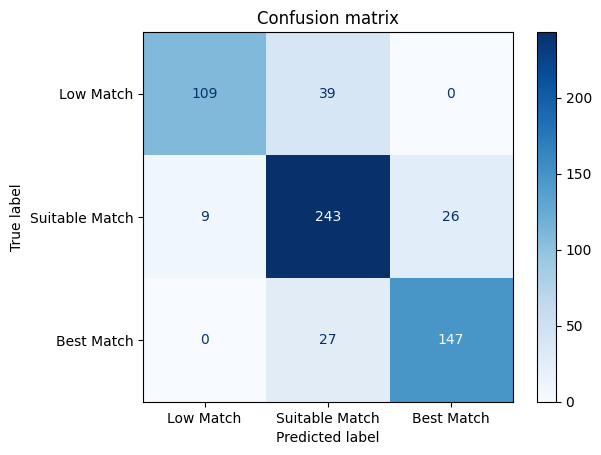

In [9]:
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=LABELS).plot(cmap='Blues')
plt.title('Confusion matrix'); plt.show()

## 5. Save the model (joblib)

In [10]:
joblib.dump(model, 'knn_ride_model.joblib')
print('saved knn_ride_model.joblib')

saved knn_ride_model.joblib


## 6. Load the saved model and predict a new ride
This is exactly what the Flask backend does for every search.

In [11]:
loaded = joblib.load('knn_ride_model.joblib')
ride = {'pickup':'Gachibowli','destination':'Hitech City','seats_available':3,'has_ac':True,'smoking_allowed':False,'music':False}
prefs = {'pref_ac':True,'pref_no_smoking':True,'pref_music':False}
row = build_feature_row('Gachibowli','Hitech City', 10, ride, prefs, 4.5)
x = pd.DataFrame([row], columns=FEATURE_COLUMNS)
print(dict(zip(FEATURE_COLUMNS,row)))
print('Prediction:', LABELS[loaded.predict(x)[0]], '| probabilities:', dict(zip(LABELS, loaded.predict_proba(x)[0].round(2))))

{'pickup_distance_km': 0.0, 'destination_distance_km': 0.0, 'time_diff_min': 10.0, 'seats_available': 3, 'preference_score': 3, 'driver_rating': 4.5}
Prediction: Best Match | probabilities: {'Low Match': np.float64(0.0), 'Suitable Match': np.float64(0.0), 'Best Match': np.float64(1.0)}
